In [ ]:
import re
from pathlib import Path
import numpy as np
import h5py
from collections import defaultdict
import matplotlib.pyplot as plt
from matplotlib import cm
import pandas as pd
from glob import glob
import sys, os
import seaborn as sns

from matplotlib.lines import Line2D
from metrics import full_map_cover_time, roi_first_visit_per_cfg, roi_first_visit_static, convergence_errors_from_run, empirical_full, empirical_soft_forget, empirical_from_traj, empirical_window


In [25]:
def parse_run_name(folder_name):
    info = {}
    info["is_mac_dt"] = "mac_dt" in folder_name
    info["is_ergodic"] = "ergodic" in folder_name
    # info["mh_method"] = "mh" if "mh" in folder_name else None
    # info["remc_method"] = "remc" if "remc" in folder_name else None
    info["gp_policy"] = "gpucb" if "gpucb" in folder_name else "gpmean"

    m = re.search(r"starts(\d+)", folder_name)
    info["starts"] = m.group(1) if m else None

    m = re.search(r"T(\d+)", folder_name)
    info["T"] = int(m.group(1)) if m else None

    return info

In [26]:
# def load_run_npz(run_dir):
#     npz_path = next(Path(run_dir).glob("run_*.npz"))
#     return np.load(npz_path, allow_pickle=True)


def load_run(run_dir):

    # ---- NPZ case ----
    npz_path = next(Path(run_dir).glob("run_*.npz"), None)
    if npz_path is not None:
        z = np.load(npz_path, allow_pickle=True)
        data = {k: z[k] for k in z.files}
        z.close()
        return data

    # ---- H5 case ----
    h5_path = Path(run_dir) / "run.h5"
    if h5_path.exists():
        data = {}
        with h5py.File(h5_path, "r") as f:

            # datasets
            for key in f.keys():
                data[key] = f[key][()]

            # attributes
            for key, val in f.attrs.items():
                data[key] = val

        return data

    raise FileNotFoundError(f"No run_*.npz or run.h5 found in {run_dir}")


In [27]:


def get_method_label(data, run_dir):

    keys = set(data.files) if hasattr(data, "files") else set(data.keys())

    # --- planner ---
    if "planner" in keys:
        planner = data["planner"].item() if hasattr(data["planner"], "item") else data["planner"]

    elif "stem" in keys:
        stem = data["stem"].item() if hasattr(data["stem"], "item") else data["stem"]
        if "mac_dt" in stem:
            planner = "mac_dt"
        elif "ergodic" in stem:
            planner = "ergodic"
        else:
            raise ValueError(f"Cannot infer planner from stem: {stem}")

    else:
        # fallback: infer from folder name
        name = run_dir.name
        if "mac_dt" in name:
            planner = "mac_dt"
        elif "ergodic" in name:
            planner = "ergodic"
        else:
            raise ValueError(f"Cannot determine planner from run: {name}")

    # --- GP mode ---
    gp_mode = None
    if "gp_mode" in keys:
        gp_mode = data["gp_mode"].item() if hasattr(data["gp_mode"], "item") else data["gp_mode"]
    else:
        if "gpucb" in run_dir.name:
            gp_mode = "gpucb"
        elif "gpmean" in run_dir.name:
            gp_mode = "gpmean"

    # --- ergodic mode (mh / remc) ---
    method = None
    if planner == "ergodic":

        if "method" in keys:
            method = data["method"].item() if hasattr(data["method"], "item") else data["method"]

        else:
            name = run_dir.name
            m = re.search(r"_([a-z]+)_Pupdate", name)
            if m:
                method = m.group(1)

    # --- final label ---
    if planner == "ergodic":
        label = f"ergodic-{method}" if method else "ergodic"
    elif planner == "mac_dt":
        label = "mac-dt"
    else:
        label = planner

    if gp_mode:
        label = f"{label}-{gp_mode}"

    return label



In [28]:
def detect_cfg_starts(true_phi_map_time, atol=1e-12):
    T = true_phi_map_time.shape[0]
    starts = [0]
    for t in range(1, T):
        if not np.allclose(true_phi_map_time[t], true_phi_map_time[t-1], atol=atol):
            starts.append(t)
    return np.array(starts, dtype=int)

def cfg_intervals_from_true_phi(true_phi_map_time, T_traj):
    cfg_starts = detect_cfg_starts(true_phi_map_time)
    T_end = min(T_traj, true_phi_map_time.shape[0])

    intervals = []
    for i, t0 in enumerate(cfg_starts):
        t1 = cfg_starts[i+1] if i+1 < len(cfg_starts) else T_end
        intervals.append((i, int(t0), int(min(t1, T_end))))
    return cfg_starts, intervals

In [61]:


def extract_map_id_from_name(run_name):
    """
    Extracts map id like 'v0', 'v1', etc. from run folder name.
    """
    m = re.search(r"_v(\d+)_", run_name)
    if m:
        return f"v{m.group(1)}"
    else:
        return None
    
def extract_start_from_name(run_name):
    """
    Extract start index from run folder name.
    Matches both 'start00' and 'starts00'.
    """
    m = re.search(r"starts?(\d+)", run_name)

    if m:
        return m.group(1)
    else:
        return None
    


sys.path.append(os.path.abspath(".."))
sys.path.append(os.getcwd())
from env.grid import make_env_from_json
def recover_state_index_map(data):
    # old npz
    if "state_index_map" in data:
        sim = data["state_index_map"]
        return sim.item() if hasattr(sim, "item") else sim

    # h5
    if "state_index_map_keys" in data and "state_index_map_vals" in data:
        keys = data["state_index_map_keys"]
        vals = data["state_index_map_vals"]
        return {tuple(k): int(v) for k, v in zip(keys, vals)}

    # reconstruct from env_source (fallback)
    env_source = data.get("env_source", None)
    if env_source is None:
        raise RuntimeError("Cannot recover state_index_map: no keys/vals or env_source")

    if isinstance(env_source, np.ndarray):
        env_source = env_source.item()

    if data.get("env_dyn", "static") == "dynamic":
        import glob as glob_mod
        json_files = sorted(glob_mod.glob(os.path.join(env_source, "*.json")))
        if not json_files:
            raise RuntimeError(f"No JSON files found in {env_source} (cwd={os.getcwd()})")
        env = make_env_from_json(json_files[0])
    else:
        env = make_env_from_json(env_source)

    env._indexing()
    env._precompute_graph()
    return env._state_index_map

In [30]:


def build_roi_cellsets(roi_rc, roi_name):
    """
    Returns dict: roi_name -> set of (r,c)
    """
    roi_sets = {}
    for (r, c), name in zip(roi_rc, roi_name):
        name = str(name)
        roi_sets.setdefault(name, set()).add((int(r), int(c)))
    return roi_sets




### Analysis of different Algorithms

In [ ]:
BATCH_DIR = Path("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/Planner_Comparison_10x10_0214")

for run_dir in BATCH_DIR.iterdir():
    data = load_run(run_dir)
    # print(run_dir)
    print(run_dir.name, "→", get_method_label(data, run_dir))

In [ ]:
cover_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    data = load_run(run_dir)

    label = get_method_label(data, run_dir)

    map_id = extract_map_id_from_name(run_dir.name)
    agent_starts = extract_start_from_name(run_dir.name)

    n_agents = int(data["n_agents"])
    nstates = int(data["nstates"])

    traj_states = data["traj_states"]
    true_phi_map_time = data["true_phi_map_time"]
    state_index_map = recover_state_index_map(data)

    full_cellset = set((int(r), int(c)) for (r, c) in state_index_map.keys())

    cfg_starts = detect_cfg_starts(true_phi_map_time)

    cover_time = full_map_cover_time(
        traj_states=traj_states,
        nstates=nstates,
    )

    cover_rows.append({
        "run": run_dir.name,
        "map_id": map_id,
        "n_agents": n_agents,
        "algorithm": label,
        "cover_time": cover_time,
        "agent_starts": agent_starts,
    })

map_df = (
    pd.DataFrame(cover_rows)
    .sort_values(["map_id", "algorithm", "n_agents", "agent_starts"])
    .reset_index(drop=True)
)

display(map_df)




In [ ]:
cover_df = map_df
cover_summary = (
    cover_df
    .groupby("algorithm", as_index=False)
    .agg(
        mean_cover_time=("cover_time", "mean"),
        std_cover_time=("cover_time", "std"),
        success_rate=("cover_time", lambda x: x.notna().mean()),
        n_runs=("cover_time", "count"),
    )
)

cover_summary

In [ ]:
roi_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run(run_dir)

    label = get_method_label(npz, run_dir)
    map_id = extract_map_id_from_name(run_dir.name)
    agent_starts = extract_start_from_name(run_dir.name)
    n_agents = int(npz["n_agents"])
    env_dyn = str(npz["env_dyn"])

    traj_rc_all = np.asarray(npz["traj_rc_agents_all"])
    true_phi_map_time = npz["true_phi_map_time"]

    roi_sets = build_roi_cellsets(npz["roi_rc"], npz["roi_name"])


    for roi_name, cellset in roi_sets.items():
        t = roi_first_visit_static(traj_rc_all, cellset)

        roi_rows.append({
            "run": run_dir.name,
            "map_id": map_id,
            "roi_name": roi_name,
            "cfg": 0,
            "roi_cover_time": t,
            "n_agents": n_agents,
            "agent_starts": agent_starts,
            "algorithm":label
        })


roi_df = pd.DataFrame(roi_rows)
roi_df = roi_df.sort_values(
    ["map_id", "algorithm", "n_agents", "cfg","roi_name"]
).reset_index(drop=True)

pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)
display(roi_df)


In [ ]:
roi_df = roi_df

roi_summary = (
    roi_df
    .groupby(["algorithm", "roi_name"], as_index=False)
    .agg(
        mean_visit_time=("roi_cover_time", "mean"),
        std_visit_time=("roi_cover_time", "std"),
        n_runs=("roi_cover_time", "count"),
    )
)

roi_summary

In [ ]:
all_roi_df = roi_df

all_roi_summary = (
    all_roi_df
    .groupby(["algorithm"], as_index=False)
    .agg(
        mean_visit_time=("roi_cover_time", "mean"),
        std_visit_time=("roi_cover_time", "std"),
        n_runs=("roi_cover_time", "count"),
    )
)

all_roi_summary

In [ ]:
curves_emp_bel  = defaultdict(list)
curves_bel_true = defaultdict(list)
curves_emp_true = defaultdict(list)
curves_regret = defaultdict(list)

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run(run_dir)
    label = get_method_label(npz, run_dir)
    state_index_map = recover_state_index_map(npz)
    nstates = len(state_index_map)

    class DummyEnv:
        def __init__(self, nstates):
            self.nstates = nstates

    env = DummyEnv(nstates)
    if "belief_phi_map_avg" in npz:
        belief_phi = npz["belief_phi_map_avg"]

    elif "belief_phi_map" in npz:
        belief_phi = npz["belief_phi_map"]

        # average if per-agent belief
        if belief_phi.ndim == 3:
            belief_phi = belief_phi.mean(axis=1)

    else:
        raise KeyError("No belief dataset found.")

    err_emp_bel, err_bel_true, err_emp_true = convergence_errors_from_run(
        traj_states=npz["traj_states"],
        belief_phi_map=belief_phi,
        true_phi_map_time=npz["true_phi_map_time"],
        env=env,
        empirical_fn=empirical_full,
    )

    curves_emp_bel[label].append(err_emp_bel)
    curves_bel_true[label].append(err_bel_true)
    regret = np.cumsum(err_emp_true) / (np.arange(len(err_emp_true)) + 1)
    curves_emp_true[label].append(err_emp_true)
    curves_regret[label].append(regret)



In [ ]:
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans"],
    "mathtext.fontset": "cm",
    "font.size": 16,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "legend.fontsize": 16,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "lines.linewidth": 2.4,
})

fig, ax = plt.subplots(figsize=(8.0, 4.8))

# color_map = {
#     "ergodic-remc-ucb": "#0072B2",
#     "mac-dt-ucb": "#000000",
# }

# method_name_map = {
#     "ergodic-remc-ucb": "Dec-Ergodic",
#     "mac-dt-ucb": "MAC-DT",
# }


color_map = {
    "ergodic-remc-ucb": "#0072B2",
    "ergodic-mh-ucb": "#000000",
}

method_name_map = {
    "ergodic-remc-ucb": "REMC",
    "ergodic-mh-ucb": "MH",
}


# ----------------------------
for label in curves_emp_bel.keys():

    if label not in color_map:
        continue

    c = color_map[label]

    # ---- regret (solid) ----
    # Ys = curves_emp_bel[label]
    Ys = curves_regret[label]
    min_len = min(len(y) for y in Ys)
    Y = np.stack([y[:min_len] for y in Ys])

    mean = Y.mean(axis=0)
    std  = Y.std(axis=0)
    x = np.arange(min_len)

    ax.plot(
        x, mean,
        color=c,
        linestyle="-",
        label=method_name_map[label]
    )

    ax.fill_between(
        x, mean - std, mean + std,
        color=c,
        alpha=0.15,
        linewidth=0
    )

    # ---- Belief vs True (dashed) ----
    Ys = curves_bel_true[label]
    min_len = min(len(y) for y in Ys)
    Y = np.stack([y[:min_len] for y in Ys])

    mean = Y.mean(axis=0)
    std  = Y.std(axis=0)

    ax.plot(
        x, mean,
        color=c,
        linestyle="--"
    )

    ax.fill_between(
        x, mean - std, mean + std,
        color=c,
        alpha=0.10,
        linewidth=0
    )


ax.set_xlabel(r"Time step $k$")
ax.set_ylabel(r"$\ell_1$ Error")

ax.grid(True, axis="y", alpha=0.25, linewidth=0.8)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)



method_handles = [
    Line2D([0], [0], color=color_map[k], lw=2.4,
           label=method_name_map[k])
    for k in color_map.keys()
]

metric_handles = [
    Line2D([0], [0], color="black", lw=2.4, linestyle="-",
           label=r"$\mathrm{Regret}_k$"),
    Line2D([0], [0], color="black", lw=2.0, linestyle="--",
           label=r"$\mathcal{L}_{belief, k}$"),
]
#label=r"$\frac{1}{k}\sum_{t=1}^{k}\|\hat{\rho}_t - \rho_t^\star\|_1$"

# leg1 = ax.legend(handles=method_handles,
#                  title="Method",
#                  loc="upper right",
#                  frameon=False)

# leg2 = ax.legend(handles=metric_handles,
#                  title="Metric",
#                  loc="upper center",
#                  frameon=False)

combined_handles = method_handles + metric_handles

ax.legend(
    handles=combined_handles,
    loc="upper right",
    frameon=True,
    ncol=2,             
    columnspacing=1.5,
    handletextpad=0.6
)

# ax.add_artist(leg1)

plt.tight_layout()
plt.show()


### Dynamic Map Comparison

In [31]:
BATCH_DIR = Path("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/Planner_dynamic_5x5_0419")

for run_dir in BATCH_DIR.iterdir():
    data = load_run(run_dir)
    # print(run_dir)
    print(run_dir.name, "→", get_method_label(data, run_dir))

T2000_mac_dt_GPupdate50_v0_gpucb_dynamic_3_start40x3_commModelocal_comm_radius5.0_concenIter5 → mac-dt-ucb
T2000_ergodic_GPupdate50_remc_Pupdate50_v0_gpucb_dynamic_3_start31x3_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T2000_ergodic_GPupdate50_remc_Pupdate50_v1_gpucb_dynamic_3_start00x3_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T2000_mac_dt_GPupdate50_v1_gpucb_dynamic_3_start00x3_commModelocal_comm_radius5.0_concenIter5 → mac-dt-ucb
T2000_ergodic_GPupdate50_remc_Pupdate50_v0_gpucb_dynamic_3_start40x3_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T2000_ergodic_GPupdate50_remc_Pupdate50_v1_gpucb_dynamic_3_start44x3_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T2000_ergodic_GPupdate50_remc_Pupdate50_v0_gpucb_dynamic_3_start23x3_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T2000_mac_dt_GPupdate50_v1_gpucb_dynamic_3_start02x3_commModelocal_comm_radius5.0_concenIter5 → mac-dt-ucb
T2000_mac_dt_GPupdate50_v0_gpucb_d

In [47]:
roi_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    data = load_run(run_dir)

    label = get_method_label(data, run_dir)
    map_id = extract_map_id_from_name(run_dir.name)
    n_agents = int(data["n_agents"])
    agent_starts = extract_start_from_name(run_dir.name)

    traj_rc = np.asarray(data["traj_rc_agents_all"])

    # Use saved env_change_steps instead of detect_cfg_starts
    if "env_change_steps" in data:
        cfg_starts = np.concatenate([[0], np.array(data["env_change_steps"], dtype=int)])
    else:
        cfg_starts = detect_cfg_starts(data["true_phi_map_time"])

    roi_sets = build_roi_cellsets(
        data.get("roi_rc", []),
        data.get("roi_name", [])
    )

    for roi_name, cellset in roi_sets.items():

        times = roi_first_visit_per_cfg(
            traj_rc=traj_rc,
            roi_cellset=cellset,
            cfg_starts=cfg_starts
        )

        for cfg_idx, t_rel in enumerate(times):

            roi_rows.append({
                "run": run_dir.name,
                "algorithm": label,
                "map_id": map_id,
                "n_agents": n_agents,
                "agent_starts": agent_starts,
                "roi_name": roi_name,
                "cfg": cfg_idx,
                "roi_first_visit_time": t_rel,
            })

roi_dyn_df = pd.DataFrame(roi_rows)


In [50]:
# Clean roi_name bytes if needed
roi_dyn_df["roi_name"] = roi_dyn_df["roi_name"].apply(
    lambda x: x.decode() if isinstance(x, bytes) else str(x)
)

# Also store the absolute cfg start times for column headers
# (grab from any run to get the cfg_starts)
sample_dir = next(d for d in BATCH_DIR.iterdir() if d.is_dir())
sample_data = load_run(sample_dir)
sample_cfg_starts = detect_cfg_starts(sample_data["true_phi_map_time"])

# Build column names like "cfg0 (t=0)", "cfg1 (t=500)", ...
cfg_col_names = {
    i: f"cfg{i} (t={int(t)})"
    for i, t in enumerate(sample_cfg_starts)
}

# Pivot: one row per (run, algorithm, map_id, n_agents, roi_name, agent_starts)
roi_wide = (
    roi_dyn_df
    .assign(cfg_label=lambda df: df["cfg"].map(cfg_col_names))
    .pivot_table(
        index=["algorithm", "map_id", "n_agents", "agent_starts", "roi_name"],
        columns="cfg_label",
        values="roi_first_visit_time",
        aggfunc="first",
    )
    .reset_index()
)

# Reorder cfg columns chronologically
cfg_cols = [cfg_col_names[i] for i in sorted(cfg_col_names) if cfg_col_names[i] in roi_wide.columns]
other_cols = [c for c in roi_wide.columns if c not in cfg_cols]
roi_wide = roi_wide[other_cols + cfg_cols]

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(roi_wide)

cfg_label,algorithm,map_id,n_agents,agent_starts,roi_name,cfg0 (t=0),cfg1 (t=500),cfg2 (t=1000),cfg3 (t=1500)
0,ergodic-remc-ucb,v0,3,23,b'roi1',17.0,9.0,30.0,48.0
1,ergodic-remc-ucb,v0,3,23,b'roi2',6.0,0.0,18.0,0.0
2,ergodic-remc-ucb,v0,3,23,b'roi3',7.0,0.0,16.0,1.0
3,ergodic-remc-ucb,v0,3,23,b'roi4',5.0,6.0,14.0,7.0
4,ergodic-remc-ucb,v0,3,23,b'roi5',0.0,9.0,53.0,2.0
5,ergodic-remc-ucb,v0,3,23,b'roi6',4.0,3.0,13.0,6.0
6,ergodic-remc-ucb,v0,3,23,b'roi7',1.0,2.0,0.0,1.0
7,ergodic-remc-ucb,v0,3,31,b'roi1',4.0,9.0,16.0,51.0
8,ergodic-remc-ucb,v0,3,31,b'roi2',17.0,0.0,1.0,0.0
9,ergodic-remc-ucb,v0,3,31,b'roi3',10.0,0.0,2.0,1.0


In [51]:
roi_dyn_summary = (
    roi_dyn_df
    .groupby(["algorithm", "roi_name", "cfg"], as_index=False)
    .agg(
        mean_time=("roi_first_visit_time", "mean"),
        std_time=("roi_first_visit_time", "std"),
        n_visited=("roi_first_visit_time", lambda x: x.notna().sum()),
        n_runs=("roi_first_visit_time", "count"),
    )
)

# Pivot the mean times wide
summary_wide = (
    roi_dyn_summary
    .assign(cfg_label=lambda df: df["cfg"].map(cfg_col_names))
    .pivot_table(
        index=["algorithm", "roi_name"],
        columns="cfg_label",
        values="mean_time",
        aggfunc="first",
    )
    .reset_index()
)

cfg_cols_s = [cfg_col_names[i] for i in sorted(cfg_col_names) if cfg_col_names[i] in summary_wide.columns]
other_cols_s = [c for c in summary_wide.columns if c not in cfg_cols_s]
summary_wide = summary_wide[other_cols_s + cfg_cols_s]

display(summary_wide)

cfg_label,algorithm,roi_name,cfg0 (t=0),cfg1 (t=500),cfg2 (t=1000),cfg3 (t=1500)
0,ergodic-remc-ucb,b'roi1',9.857143,40.571429,30.428571,34.285714
1,ergodic-remc-ucb,b'roi2',15.714286,0.000000,3.428571,1.142857
2,ergodic-remc-ucb,b'roi3',13.000000,0.428571,3.142857,0.571429
3,ergodic-remc-ucb,b'roi4',15.857143,3.428571,4.142857,3.428571
4,ergodic-remc-ucb,b'roi5',11.714286,21.000000,24.285714,1.142857
5,ergodic-remc-ucb,b'roi6',14.000000,3.428571,25.857143,5.142857
6,ergodic-remc-ucb,b'roi7',29.750000,1.250000,18.000000,1.000000
7,mac-dt-ucb,b'roi1',3.333333,193.500000,0.000000,71.333333
8,mac-dt-ucb,b'roi2',51.200000,0.800000,0.800000,0.800000
9,mac-dt-ucb,b'roi3',3.000000,0.200000,0.200000,0.200000


In [62]:
# ---- Convergence curves (dynamic) ----
curves_emp_bel_dyn  = defaultdict(list)
curves_bel_true_dyn = defaultdict(list)
curves_emp_true_dyn = defaultdict(list)
curves_regret_dyn   = defaultdict(list)

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    data = load_run(run_dir)


    
    label = get_method_label(data, run_dir)
    
    state_index_map = recover_state_index_map(data)
    nstates = len(state_index_map)

    class DummyEnv:
        def __init__(self, nstates):
            self.nstates = nstates
    env = DummyEnv(nstates)

    if "belief_phi_map_avg" in data:
        belief_phi = data["belief_phi_map_avg"]
    elif "belief_phi_map" in data:
        belief_phi = data["belief_phi_map"]
        if belief_phi.ndim == 3:
            belief_phi = belief_phi.mean(axis=1)
    else:
        raise KeyError("No belief dataset found.")

    err_emp_bel, err_bel_true, err_emp_true = convergence_errors_from_run(
        traj_states=data["traj_states"],
        belief_phi_map=belief_phi,
        true_phi_map_time=data["true_phi_map_time"],
        env=env,
        empirical_fn=empirical_full,
    )

    curves_emp_bel_dyn[label].append(err_emp_bel)
    curves_bel_true_dyn[label].append(err_bel_true)
    curves_emp_true_dyn[label].append(err_emp_true)
    regret = np.cumsum(err_emp_true) / (np.arange(len(err_emp_true)) + 1)
    curves_regret_dyn[label].append(regret)

/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/viz/metrics.py:118: RuntimeWarning: invalid value encountered in divide
  belief_norm = belief_phi_map / belief_phi_map.sum(axis=1, keepdims=True)
/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/viz/metrics.py:119: RuntimeWarning: invalid value encountered in divide
  true_norm   = true_phi_map_time / true_phi_map_time.sum(axis=1, keepdims=True)


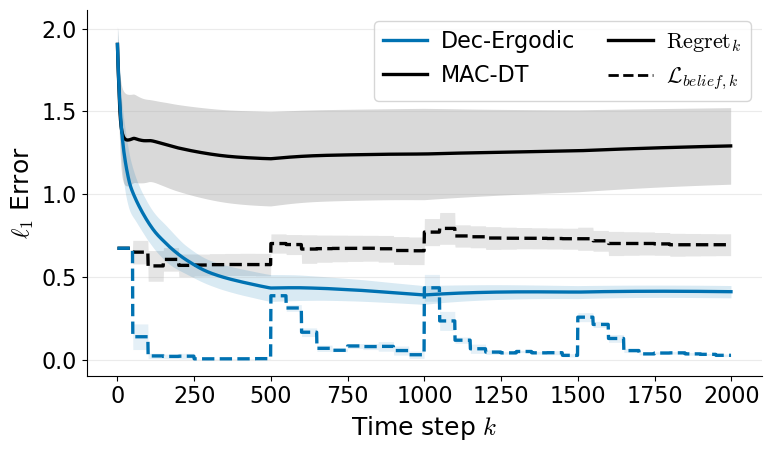

In [67]:

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans"],
    "mathtext.fontset": "cm",
    "font.size": 16,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "legend.fontsize": 16,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "lines.linewidth": 2.4,
})

fig, ax = plt.subplots(figsize=(8.0, 4.8))

color_map = {
    "ergodic-remc-ucb": "#0072B2",
    "mac-dt-ucb": "#000000",
}

method_name_map = {
    "ergodic-remc-ucb": "Dec-Ergodic",
    "mac-dt-ucb": "MAC-DT",
}


# color_map = {
#     "ergodic-remc-ucb": "#0072B2",
#     "ergodic-mh-ucb": "#000000",
# }

# method_name_map = {
#     "ergodic-remc-ucb": "REMC",
#     "ergodic-mh-ucb": "MH",
# }


# ----------------------------
for label in curves_emp_bel_dyn.keys():

    if label not in color_map:
        continue

    c = color_map[label]

    # ---- regret (solid) ----
    # Ys = curves_emp_bel[label]
    Ys = curves_regret_dyn[label]
    min_len = min(len(y) for y in Ys)
    Y = np.stack([y[:min_len] for y in Ys])

    mean = Y.mean(axis=0)
    std  = Y.std(axis=0)
    x = np.arange(min_len)

    ax.plot(
        x, mean,
        color=c,
        linestyle="-",
        label=method_name_map[label]
    )

    ax.fill_between(
        x, mean - std, mean + std,
        color=c,
        alpha=0.15,
        linewidth=0
    )

    # ---- Belief vs True (dashed) ----
    Ys = curves_bel_true_dyn[label]
    min_len = min(len(y) for y in Ys)
    Y = np.stack([y[:min_len] for y in Ys])

    mean = Y.mean(axis=0)
    std  = Y.std(axis=0)

    ax.plot(
        x, mean,
        color=c,
        linestyle="--"
    )

    ax.fill_between(
        x, mean - std, mean + std,
        color=c,
        alpha=0.10,
        linewidth=0
    )


ax.set_xlabel(r"Time step $k$")
ax.set_ylabel(r"$\ell_1$ Error")

ax.grid(True, axis="y", alpha=0.25, linewidth=0.8)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)



method_handles = [
    Line2D([0], [0], color=color_map[k], lw=2.4,
           label=method_name_map[k])
    for k in color_map.keys()
]

metric_handles = [
    Line2D([0], [0], color="black", lw=2.4, linestyle="-",
           label=r"$\mathrm{Regret}_k$"),
    Line2D([0], [0], color="black", lw=2.0, linestyle="--",
           label=r"$\mathcal{L}_{belief, k}$"),
]
#label=r"$\frac{1}{k}\sum_{t=1}^{k}\|\hat{\rho}_t - \rho_t^\star\|_1$"

# leg1 = ax.legend(handles=method_handles,
#                  title="Method",
#                  loc="upper right",
#                  frameon=False)

# leg2 = ax.legend(handles=metric_handles,
#                  title="Metric",
#                  loc="upper center",
#                  frameon=False)

combined_handles = method_handles + metric_handles

ax.legend(
    handles=combined_handles,
    loc="upper right",
    frameon=True,
    ncol=2,             
    columnspacing=1.5,
    handletextpad=0.6
)

# ax.add_artist(leg1)

plt.tight_layout()
plt.show()

# Mark config changes with vertical lines
sample_dir = next(d for d in BATCH_DIR.iterdir() if d.is_dir())
sample_data = load_run(sample_dir)

if "env_change_steps" in sample_data:
    change_steps = sample_data["env_change_steps"]
else:
    change_steps = detect_cfg_starts(sample_data["true_phi_map_time"])[1:]

for t_change in change_steps:
    ax.axvline(t_change, color="gray", linestyle=":", linewidth=1.2, alpha=0.7)

# Add to legend
metric_handles.append(
    Line2D([0], [0], color="gray", lw=1.2, linestyle=":", label="Map change")
)

In [64]:
# ---- Convergence curves (dynamic) — three empirical functions ----

empirical_fns = {
    "full":        (empirical_full,        {}),
    "window-100":  (empirical_window,      {"window": 100}),
    "soft-γ=0.98": (empirical_soft_forget, {"gamma": 0.98}),
}

# {emp_fn_name: {label: [regret_array, ...]}}
curves_by_emp = {
    name: defaultdict(list) for name in empirical_fns
}
curves_bel_true_dyn = defaultdict(list)  # belief vs true (same for all emp fns)

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    data = load_run(run_dir)
    label = get_method_label(data, run_dir)
    state_index_map = recover_state_index_map(data)
    nstates = len(state_index_map)

    class DummyEnv:
        def __init__(self, nstates):
            self.nstates = nstates
    env = DummyEnv(nstates)

    if "belief_phi_map_avg" in data:
        belief_phi = data["belief_phi_map_avg"]
    elif "belief_phi_map" in data:
        belief_phi = data["belief_phi_map"]
        if belief_phi.ndim == 3:
            belief_phi = belief_phi.mean(axis=1)
    else:
        raise KeyError("No belief dataset found.")

    for emp_name, (emp_fn, emp_kwargs) in empirical_fns.items():
        err_emp_bel, err_bel_true, err_emp_true = convergence_errors_from_run(
            traj_states=data["traj_states"],
            belief_phi_map=belief_phi,
            true_phi_map_time=data["true_phi_map_time"],
            env=env,
            empirical_fn=emp_fn,
            empirical_kwargs=emp_kwargs,
        )

        regret = np.cumsum(err_emp_true) / (np.arange(len(err_emp_true)) + 1)
        curves_by_emp[emp_name][label].append(regret)

        # belief vs true is independent of empirical fn, only store once
        if emp_name == "full":
            curves_bel_true_dyn[label].append(err_bel_true)

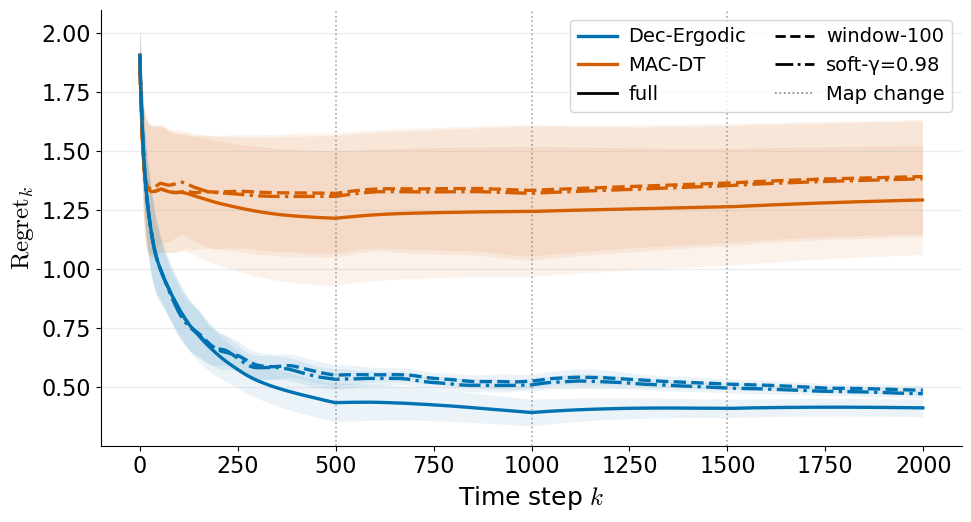

In [65]:
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans"],
    "mathtext.fontset": "cm",
    "font.size": 16,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "legend.fontsize": 14,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "lines.linewidth": 2.4,
})

algo_colors = {
    "ergodic-remc-ucb": "#0072B2",
    "mac-dt-ucb":       "#D55E00",
}

algo_names = {
    "ergodic-remc-ucb": "Dec-Ergodic",
    "mac-dt-ucb":       "MAC-DT",
}

emp_linestyles = {
    "full":        "-",
    "window-100":  "--",
    "soft-γ=0.98": "-.",
}

fig, ax = plt.subplots(figsize=(10, 5.5))

for emp_name, ls in emp_linestyles.items():
    for label, Ys in curves_by_emp[emp_name].items():
        if label not in algo_colors:
            continue

        c = algo_colors[label]
        min_len = min(len(y) for y in Ys)
        Y = np.stack([y[:min_len] for y in Ys])

        mean = Y.mean(axis=0)
        std  = Y.std(axis=0)
        x = np.arange(min_len)

        ax.plot(x, mean, color=c, linestyle=ls)
        ax.fill_between(x, mean - std, mean + std,
                         color=c, alpha=0.08, linewidth=0)

# ---- Config-change vertical lines ----
sample_dir = next(d for d in BATCH_DIR.iterdir() if d.is_dir())
sample_data = load_run(sample_dir)

if "env_change_steps" in sample_data:
    change_steps = sample_data["env_change_steps"]
else:
    change_steps = detect_cfg_starts(sample_data["true_phi_map_time"])[1:]

for t_change in change_steps:
    ax.axvline(t_change, color="gray", linestyle=":", linewidth=1.2, alpha=0.7)

ax.set_xlabel(r"Time step $k$")
ax.set_ylabel(r"$\mathrm{Regret}_k$")
ax.grid(True, axis="y", alpha=0.25, linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ---- Legend ----
algo_handles = [
    Line2D([0], [0], color=algo_colors[k], lw=2.4, label=algo_names[k])
    for k in algo_colors if k in curves_by_emp["full"]
]

emp_handles = [
    Line2D([0], [0], color="black", lw=2.0, linestyle=ls, label=name)
    for name, ls in emp_linestyles.items()
]

other_handles = [
    Line2D([0], [0], color="gray", lw=1.2, linestyle=":", label="Map change"),
]

ax.legend(
    handles=algo_handles + emp_handles + other_handles,
    loc="upper right",
    frameon=True,
    ncol=2,
    columnspacing=1.5,
    handletextpad=0.6,
)

plt.tight_layout()
plt.show()

### Analysis of communication radius effect in Ergodic 

In [ ]:
BATCH_DIR = Path("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/Analysis_Comms_Init6_021126")
for run_dir in list(BATCH_DIR.iterdir()):
    npz = load_run_npz(run_dir)
    print(run_dir.name, "→", get_method_label(npz))
print(len(list(BATCH_DIR.iterdir())))

In [ ]:
roi_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    traj_rc_all = np.asarray(npz["traj_rc_agents_all"])
    true_phi_map_time = npz["true_phi_map_time"]
    env_dyn = str(npz["env_dyn"])

    map_id = extract_map_id_from_name(run_dir.name)
    n_agents = int(npz["n_agents"])
    comm_radius = npz["comm_radius"].item()
    agent_starts = extract_start_from_name(run_dir.name)

    roi_sets = build_roi_cellsets(
        npz.get("roi_rc", []),
        npz.get("roi_name", [])
    )


    # normally these are run static but if dynamic needed call the other function
    for roi_name, cellset in roi_sets.items():
        t = roi_first_visit_static(traj_rc_all, cellset)

        roi_rows.append({
            "run": run_dir.name,
            "map_id": map_id,
            "roi_name": roi_name,
            "cfg": 0,
            "roi_cover_time": t,
            "comm_radius": comm_radius,
            "n_agents": n_agents,
            "agent_starts": agent_starts,
        })




roi_df = pd.DataFrame(roi_rows)

from IPython.display import display
# display(roi_df)
with pd.option_context("display.max_rows", None):
    display(roi_df)



In [ ]:

# roi_summary = (
#     roi_df
#     .groupby(["comm_radius", "roi_name"], as_index=False) #averaging over
#     .agg(
#         mean_cover_time=("roi_cover_time", "mean"),
#         std_cover_time=("roi_cover_time", "std"),
#         n_runs=("roi_cover_time", "count"),
#     ) 
# )

roi_summary = (
    roi_df
    .groupby(["n_agents", "comm_radius", "roi_name"], as_index=False) #averaging over
    .agg(
        mean_cover_time=("roi_cover_time", "mean"),
        std_cover_time=("roi_cover_time", "std"),
        n_runs=("roi_cover_time", "count"),
    ) 
)


# roi_summary_median = (
#     roi_df
#     .groupby(["n_agents", "comm_radius", "roi_name"], as_index=False)
#     .agg(
#         median_cover_time=("roi_cover_time", "median"),
#         iqr_cover_time=("roi_cover_time", lambda x: x.quantile(0.75) - x.quantile(0.25)),
#     )
# )
# roi_df["roi_cover_time_norm"] = (
#     roi_df["roi_cover_time"]
#     / roi_df.groupby(["map_id", "roi_name"])["roi_cover_time"].transform("median")
# )

roi_summary_norm = (
    roi_df
    .groupby(["n_agents", "comm_radius"], as_index=False)
    .agg(
        mean_norm_time=("roi_cover_time_norm", "mean"),
        std_norm_time=("roi_cover_time_norm", "std"),
    )
)

display(roi_summary)

In [ ]:
display(roi_summary_norm)

In [ ]:

sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.25   
)

g = sns.catplot(
    data=roi_df,
    x="comm_radius",
    y="roi_cover_time",
    col="n_agents",
    kind="box",
    showfliers=False,
    height=3.2,      
    aspect=1.1,       
    width=0.25,
    color="#4C72B0", 
    linewidth=1.4,
    boxprops=dict(alpha=0.8),
    whiskerprops=dict(linewidth=1.2),
    capprops=dict(linewidth=1.2),
    medianprops=dict(color="black", linewidth=1.6),
)

g.set_axis_labels(
    "Communication radius",
    "ROI coverage time"
)


g.set_titles(r"$N = {col_name}$ UAVs")

# Clean spines (IEEE style)
for ax in g.axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()




In [ ]:
cover_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    traj_states = npz["traj_states"]    
    n_agents = int(npz["n_agents"])
    nstates = int(npz["nstates"])
    assert str(npz["env_dyn"]) == "static", "Currently only supports static envs for full map coverage time"


    n_agents = int(npz["n_agents"])
    comm_radius = npz["comm_radius"].item()
    map_id = extract_map_id_from_name(run_dir.name)
    agent_starts = extract_start_from_name(run_dir.name)


    cover_time = full_map_cover_time(
        traj_states=traj_states,
        nstates=nstates,
    )

    cover_rows.append({
        "run": run_dir.name,
        "map_id": map_id,
        "n_agents": n_agents,
        "comm_radius": comm_radius,
        "cover_time": cover_time,
        "agent_starts": agent_starts,
    })



cover_df = pd.DataFrame(cover_rows)

from IPython.display import display
display(cover_df)


In [ ]:
cover_df["covered"] = cover_df["cover_time"].notna()

cover_summary = (
    cover_df
    .groupby(["n_agents", "comm_radius"], as_index=False)
    .agg(
        n_runs=("cover_time", "count"),
        success_rate=("covered", "mean"),
        mean_cover_time=("cover_time", "mean"),
        std_cover_time=("cover_time", "std"),
    )
)

cover_summary

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.2,   
)

g = sns.catplot(
    data=cover_df,
    x="comm_radius",
    y="cover_time",
    col="n_agents",
    kind="box",
    showfliers=False,
    height=3.2,        
    aspect=1.1,
    width=0.25,
    color="#4C72B0",  
    linewidth=1.0,
    boxprops=dict(alpha=0.7),
    whiskerprops=dict(linewidth=1.0),
    capprops=dict(linewidth=1.0),
    medianprops=dict(color="black", linewidth=1.4),
)

g.set_axis_labels(
    "Communication radius",
    "Full map coverage time"
)

# g.set_titles("UAVs = {col_name}")
g.set_titles(" ")

# Clean spines
for ax in g.axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("full_map_coverage_vs_comm_radius.pdf", bbox_inches="tight")
plt.show()




### KL Divergence

In [ ]:
BATCH_DIR = Path("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/Analysis_Comms_Init6_021126")
for run_dir in list(BATCH_DIR.iterdir()):
    npz = load_run_npz(run_dir)
    print(run_dir.name, "→", get_method_label(npz))
print(len(list(BATCH_DIR.iterdir())))

In [ ]:
def kl_divergence(p, q, eps=1e-12):
    p = np.clip(p, eps, None)
    q = np.clip(q, eps, None)
    return np.sum(p * np.log(p / q))

In [ ]:
rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    n_agents = int(npz["n_agents"])
    comm_radius = float(npz["comm_radius"])

    phi_agents_time = npz["phi_agents_time"]   # (T, n_agents, nstates)
    gp_update_steps = npz["gp_update_steps"]   # (n_updates,)

    for t in gp_update_steps:
        phis = phi_agents_time[t]  # (n_agents, nstates)

        # normalize defensively
        phis = phis / phis.sum(axis=1, keepdims=True)

        phi_mean = phis.mean(axis=0)

        kl_vals = [
            kl_divergence(phis[a], phi_mean)
            for a in range(n_agents)
        ]

        rows.append({
            "time": int(t),
            "kl_mean": float(np.mean(kl_vals)),
            "kl_std": float(np.std(kl_vals)),
            "n_agents": n_agents,
            "comm_radius": comm_radius,
            "run": run_dir.name,
        })

kl_df = pd.DataFrame(rows)


In [ ]:
import matplotlib as mpl
import seaborn as sns
import matplotlib.pyplot as plt

g = sns.relplot(
    data=kl_df,
    x="time",
    y="kl_mean",
    hue="comm_radius",
    col="n_agents",
    kind="line",
    palette="colorblind",
    height=4,
    aspect=1.0,
    facet_kws=dict(sharey=True, sharex=True),
)

# IEEE-style axis labels
g.set_axis_labels(
    "Time Step $k$",
    r"$D_{\mathrm{KL}}\!\left(\rho_k^{m} \,\|\, \bar{\rho}_k\right)$"

)

g.set_titles(r"$N = {col_name}$ UAVs")

# --- Legend formatting ---
g._legend.set_title(r"$R_{\mathrm{comms}}$")
g._legend.set_bbox_to_anchor((0.98, 0.85))   # top-right inside figure
g._legend._loc = 1  # 1 = 'upper right'
g._legend.set_frame_on(True)
# g._legend.set_ncol(len(kl_df["comm_radius"].unique()))

# Remove top/right spines
for ax in g.axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()


In [ ]:
g = sns.relplot(
    data=kl_df,
    x="time",
    y="kl_mean",
    hue="comm_radius",
    row="n_agents",                 # ← changed from col to row
    kind="line",
    palette="colorblind",
    height=3.2,                     # slightly smaller height per subplot
    aspect=1.6,                     # make wider since now stacked
    facet_kws=dict(sharey=True, sharex=True),
)

# IEEE-style axis labels
g.set_axis_labels(
    "Time Step $k$",
    r"$D_{\mathrm{KL}}\!\left(\rho_k^{m} \,\|\, \bar{\rho}_k\right)$"
)

g.set_titles(r"$N = {row_name}$ UAVs")   # use row_name instead of col_name

# Legend formatting
g._legend.set_title(r"$R_{\mathrm{comms}}$")
g._legend.set_bbox_to_anchor((0.98, 0.98))
g._legend._loc = 1
g._legend.set_frame_on(True)

# Clean spines
for ax in g.axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()


In [ ]:
rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    n_agents = int(npz["n_agents"])
    comm_radius = float(npz["comm_radius"])

    T = int(npz["T"])

    for t in range(T):


        rows.append({
            "time": t,
            # "coverage": frac,
            "n_agents": n_agents,
            "comm_radius": comm_radius,
            "run": run_dir.name,
        })

cov_df = pd.DataFrame(rows)


In [ ]:
cov_df = pd.DataFrame(rows)
g = sns.relplot(
    data=cov_df,
    x="time",
    y="coverage",
    hue="comm_radius",
    col="n_agents",
    kind="line",
    palette="colorblind",
    height=4,
    aspect=1.0,
)


g.set_axis_labels("Timestep", "Fraction of map explored")
# g.set_titles("UAVs = {col_name}")
g.set_titles(" ")

for ax in g.axes.flat:
    ax.set_ylim(0.9, 1.01)   
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("fracKL_.png", bbox_inches="tight")
plt.show()


In [ ]:
cov_df_500 = cov_df[cov_df["time"] <= 500]
g = sns.relplot(
    data=cov_df_500,
    x="time",
    y="coverage",
    hue="comm_radius",
    col="n_agents",
    kind="line",
    palette="colorblind",
    height=4,
    aspect=1.0,
)

g.set_axis_labels("Time", "Fraction of map explored")
# g.set_titles("Number of UAVs = {col_name}")
g.set_titles(" ")

for ax in g.axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()


### Analysis P Matrix

In [ ]:
BATCH_DIR = Path("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/P_GP_update_randomchange")
for run_dir in list(BATCH_DIR.iterdir()):
    print(run_dir.name)
    npz = load_run_npz(run_dir)

print(len(list(BATCH_DIR.iterdir())))

In [ ]:
roi_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    traj_rc = np.asarray(npz["traj_rc_agents_all"])   # (T, n_agents, 2)
    true_phi_map_time = npz["true_phi_map_time"]
    n_agents = int(npz["n_agents"])
    map_id = extract_map_id_from_name(run_dir.name)
    agent_starts = extract_start_from_name(run_dir.name)

    # cfg starts (absolute times)
    cfg_starts = detect_cfg_starts(true_phi_map_time)
    cfg_cols = [f"cfg{i}_t={cfg_starts[i]}" for i in range(len(cfg_starts))]

    # ROI geometry sets (r,c)
    roi_sets = build_roi_cellsets(
        npz.get("roi_rc", []),
        npz.get("roi_name", [])
    )

    for roi_name, cellset in roi_sets.items():
        # canonical metric call: returns one value per cfg (offset relative to cfg start)
        t_rel_vec = roi_first_visit_per_cfg(
            traj_rc=traj_rc,
            roi_cellset=cellset,
            cfg_starts=cfg_starts,
        )
        # print(f"Run {run_dir.name}, ROI {roi_name}, t_rel_vec: {t_rel_vec}")
        if t_rel_vec is None or np.isnan(t_rel_vec).any():
            print(f"Run {run_dir.name}, ROI {roi_name} with Nan")

        row = {
            "map_id": map_id,
            "agent_starts": agent_starts,
            # "run": run_dir.name,
            "n_agents": n_agents,
            "gp_update": int(npz["gp_update"]),
            "p_update": int(npz["p_update"]),
            "roi": roi_name,
        }

        # write into columns
        for i, col in enumerate(cfg_cols):
            row[col] = t_rel_vec[i]  # may be np.nan

        roi_rows.append(row)

roi_df = (
    pd.DataFrame(roi_rows)
    .sort_values(["n_agents", "gp_update", "p_update", "roi", "map_id", "agent_starts"])
    .reset_index(drop=True)
)

with pd.option_context("display.max_rows", None):
    display(roi_df)



In [ ]:

cover_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    traj_states = npz["traj_states"]       
    n_agents = int(npz["n_agents"])
    nstates = int(npz["nstates"])

    map_id = extract_map_id_from_name(run_dir.name)
    agent_starts = extract_start_from_name(run_dir.name)

    cover_time = full_map_cover_time(
        traj_states=traj_states,
        nstates=nstates,
    )

    cover_rows.append({
        "map_id": map_id,
        "agent_starts": agent_starts,
        "n_agents": n_agents,
        "gp_update": int(npz["gp_update"]),
        "p_update": int(npz["p_update"]),
        "full_map_cover_time": cover_time,
    })

cover_df = (
    pd.DataFrame(cover_rows)
    .sort_values(["n_agents", "gp_update", "p_update", "map_id", "agent_starts"])
    .reset_index(drop=True)
)

with pd.option_context("display.max_rows", None):
    display(cover_df)

In [ ]:
curves = defaultdict(lambda: {
    "emp_bel": [],
    "bel_true": [],
    "emp_true": [],
    "regret": []
})

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    data = load_run_npz(run_dir)


    state_index_map = recover_state_index_map(data)
    nstates = len(state_index_map)

    class DummyEnv:
        def __init__(self, nstates):
            self.nstates = nstates

    env = DummyEnv(nstates)

    err_emp_bel, err_bel_true, err_emp_true = convergence_errors_from_run(
        traj_states=data["traj_states"],
        belief_phi_map=data["belief_phi_map"],
        true_phi_map_time=data["true_phi_map_time"],
        env=env,
        empirical_fn=empirical_full,
    )

    key = (
        int(data["n_agents"]),
        int(data["gp_update"]),
        int(data["p_update"]),
    )

    curves[key]["emp_bel"].append(err_emp_bel)
    curves[key]["bel_true"].append(err_bel_true)
    curves[key]["emp_true"].append(err_emp_true)
    regret = np.cumsum(err_emp_true) / (np.arange(len(err_emp_true)) + 1)
    curves[key]["regret"].append(regret)



In [ ]:
plt.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 18,
    "axes.titlesize": 20,
    "legend.fontsize": 14,
    "lines.linewidth": 2.2,
})


update_pairs = sorted({
    (gp_u, p_u)
    for (n_agents, gp_u, p_u) in curves.keys()
})

base_colors = [
    "#1f77b4",  # blue
    "#ff7f0e",  # orange
    "#2ca02c",  # dark green
    "#9467bd",  # purple
    "#d62728",  # muted red
    "#8c564b",  # brown
    "#e377c2",  # pink
]

if len(update_pairs) > len(base_colors):
    raise ValueError(
        f"Need {len(update_pairs)} colors but only {len(base_colors)} provided. "
        "Add more colors explicitly."
    )

color_map = {
    pair: base_colors[i]
    for i, pair in enumerate(update_pairs)
}

all_n_agents = sorted({k[0] for k in curves.keys()})
target_n_agents = all_n_agents[0]   # change if needed

items = [
    (k, v) for k, v in curves.items()
    if k[0] == target_n_agents
]

fig, ax = plt.subplots(figsize=(10, 5))

for (n_agents, gp_u, p_u), data in items:
    color = color_map[(gp_u, p_u)]

    # ---------- empirical vs true---------

    # Y = data["emp_true"]
    Y = data["regret"]
    min_len = min(len(y) for y in Y)
    Y = np.stack([y[:min_len] for y in Y])

    mean = Y.mean(axis=0)
    std  = Y.std(axis=0)
    x = np.arange(min_len)

    ax.plot(x, mean, color=color, ls="-")
    ax.fill_between(
        x,
        mean - std,
        mean + std,
        color=color,
        alpha=0.10,
        linewidth=0,
    )

    # ---------- belief vs true ----------
    Y2 = data["bel_true"]
    min_len2 = min(len(y) for y in Y2)
    min_len_common = min(min_len, min_len2)

    Y2 = np.stack([y[:min_len_common] for y in Y2])
    mean2 = Y2.mean(axis=0)
    std2  = Y2.std(axis=0)

    ax.plot(
        x[:min_len_common],
        mean2,
        color=color,
        ls="--",
    )
    ax.fill_between(
        x[:min_len_common],
        mean2 - std2,
        mean2 + std2,
        color=color,
        alpha=0.10,
        linewidth=0,
    )


ax.set_xlabel("Time step k")
ax.set_ylabel(r"$\mathrm{Regret}_k$")
ax.yaxis.set_major_locator(plt.MultipleLocator(0.25))
# ax.set_title(f"Convergence ({target_n_agents} agent{'s' if target_n_agents > 1 else ''})")
ax.set_xscale("log")
ax.grid(True, axis="y", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


update_handles = [
    Line2D(
        [0], [0],
        color=color_map[pair],
        lw=2.2,
        label=rf"$\tau_{{GP}}={pair[0]},\ \tau_{{P}}={pair[1]}$"
    )
    for pair in update_pairs
]

metric_handles = [
    Line2D(
        [0], [0],
        color="black",
        lw=2.2,
        ls="-",
        label=r"$\|\hat{\rho}_k - \rho_k^\star\|_1$"
    ),
    Line2D(
        [0], [0],
        color="black",
        lw=2.2,
        ls="--",
        label=r"$\|\bar{\rho}_k - \rho_k^\star\|_1$"
    ),
]

leg1 = ax.legend(
    handles=update_handles,
    title="Update frequency",
    loc="upper right",
    frameon=False,
)

leg2 = ax.legend(
    handles=metric_handles,
    title="Metric",
    loc="upper center",
    frameon=False,
)

ax.add_artist(leg1)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# --------------------------------------------------
# IEEE-style settings
# --------------------------------------------------
plt.rcParams.update({
    "font.size": 19,
    "axes.labelsize": 20,
    "axes.titlesize": 20,
    "legend.fontsize": 19,
    "lines.linewidth": 2.2,
})

# --------------------------------------------------
# Colorblind-safe palette (Okabe–Ito)
# --------------------------------------------------
colorblind_colors = [
    "#0072B2",  # blue
    "#D55E00",  # vermillion
    "#009E73",  # bluish green
    "#CC79A7",  # reddish purple
    # "#d62728",  # muted red
    
]

linestyles = ["-", "--", "-.", ":"]

update_pairs = sorted({
    (gp_u, p_u)
    for (n_agents, gp_u, p_u) in curves.keys()
})

if len(update_pairs) > len(colorblind_colors):
    raise ValueError("Add more colors for update settings.")

color_map = {
    pair: colorblind_colors[i]
    for i, pair in enumerate(update_pairs)
}

ls_map = {
    pair: linestyles[i]
    for i, pair in enumerate(update_pairs)
}


all_n_agents = sorted({k[0] for k in curves.keys()})
target_n_agents = all_n_agents[0]

items = [
    (k, v) for k, v in curves.items()
    if k[0] == target_n_agents
]


fig, (ax1, ax2, ax3) = plt.subplots(
    3, 1,
    figsize=(11, 11),
    sharex=True
)

# ==================================================
# TOp: REGRET
# ==================================================
for (n_agents, gp_u, p_u), data in items:

    color = color_map[(gp_u, p_u)]
    ls = ls_map[(gp_u, p_u)]

    # Y = data["emp_true"]
    Y = data["regret"]
    min_len = min(len(y) for y in Y)
    Y = np.stack([y[:min_len] for y in Y])

    mean = Y.mean(axis=0)
    std  = Y.std(axis=0)
    x = np.arange(min_len)

    ax1.plot(x, mean, color=color, ls=ls)
    ax1.fill_between(
        x,
        mean - std,
        mean + std,
        color=color,
        alpha=0.05,     
        linewidth=0
    )

# ax1.set_ylabel(r"$\|\hat{\rho}_k - \rho_k^\star\|_1$")
# ax1.set_ylabel(
#     r"$\frac{1}{k}\sum_{t=1}^{k}\|\hat{\rho}_t - \rho_t^\star\|_1$"
# )
ax1.set_ylabel(r"$\mathrm{Regret}_k$")
# ax1.set_yscale("log")
ax1.grid(True, axis="y", alpha=0.25)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)


# ==================================================
# TOP: Empirical vs True
# ==================================================
for (n_agents, gp_u, p_u), data in items:

    color = color_map[(gp_u, p_u)]
    ls = ls_map[(gp_u, p_u)]

    Y = data["emp_true"]
    # Y = data["regret"]
    min_len = min(len(y) for y in Y)
    Y = np.stack([y[:min_len] for y in Y])

    mean = Y.mean(axis=0)
    std  = Y.std(axis=0)
    x = np.arange(min_len)

    ax2.plot(x, mean, color=color, ls=ls)
    ax2.fill_between(
        x,
        mean - std,
        mean + std,
        color=color,
        alpha=0.05,     
        linewidth=0
    )

# ax1.set_ylabel(r"$\|\hat{\rho}_k - \rho_k^\star\|_1$")
# ax1.set_ylabel(
#     r"$\frac{1}{k}\sum_{t=1}^{k}\|\hat{\rho}_t - \rho_t^\star\|_1$"
# )
ax2.set_ylabel(r"$\|\hat{\rho}_k - \rho_k^\star\|_1$")
# ax1.set_ylabel(r"$\mathrm{Regret}_k$")
# ax1.set_yscale("log")
ax2.grid(True, axis="y", alpha=0.25)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)


# ==================================================
# BOTTOM: Belief vs True
# ==================================================
for (n_agents, gp_u, p_u), data in items:

    color = color_map[(gp_u, p_u)]
    ls = ls_map[(gp_u, p_u)]

    Y = data["bel_true"]
    min_len = min(len(y) for y in Y)
    Y = np.stack([y[:min_len] for y in Y])

    mean = Y.mean(axis=0)
    std  = Y.std(axis=0)
    x = np.arange(min_len)

    ax3.plot(x, mean, color=color, ls=ls)
    ax3.fill_between(
        x,
        mean - std,
        mean + std,
        color=color,
        alpha=0.05,
        linewidth=0
    )

# ax2.set_ylabel(r"$\|\bar{\rho}_k - \rho_k^\star\|_1$")
ax3.set_ylabel(r"$\mathcal{L}_{belief, k}$")
ax3.set_xlabel(r"Time step $k$")

ax3.grid(True, axis="y", alpha=0.25)

ax3.spines["top"].set_visible(False)
ax3.spines["right"].set_visible(False)

# ==================================================
# Legend
# ==================================================
# legend_handles = [
#     Line2D(
#         [0], [0],
#         color=color_map[pair],
#         lw=2.6,
#         ls=ls_map[pair],
#         label=f"GP={pair[0]}, P={pair[1]}"
#     )
#     for pair in update_pairs
# ]
legend_handles  = [
    Line2D(
        [0], [0],
        color=color_map[pair],
        lw=2.6,
        ls=ls_map[pair],
        label=rf"$\tau_{{GP}}={pair[0]},\ \tau_{{P}}={pair[1]}$"
    )
    for pair in update_pairs
]

ax1.legend(
    handles=legend_handles,
    title="Update frequency",
    loc="upper right",
    frameon=False,
)

plt.tight_layout()
plt.show()

